<a href="https://colab.research.google.com/github/LikithaSrinivasa25/ml-dl-algorithms/blob/main/deep-learning/RESNET50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

RESNET 50

In [ ]:
import os
import glob as gb
import numpy as np
from keras.preprocessing.image import ImageDataGenerator
import tensorflow.keras as keras
from keras import layers
from keras.layers import Input, Dense, Activation,BatchNormalization, Flatten, Conv2D, MaxPooling2D,Dropout
from keras.models import Model,Sequential
from keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
from matplotlib.pyplot import imshow
from tensorflow.keras.utils import plot_model

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
train_dir="/content/drive/MyDrive/Image_classification/train"
test_dir="/content/drive/MyDrive/Image_classification/test"


In [ ]:
for folder in os.listdir(train_dir):
  file=gb.glob(pathname=str(train_dir+"/"+folder+"/*jpg"))
  print(f"The number of {len(file)} in the folder {folder}")

The number of 79 in the folder cats
The number of 194 in the folder dog
The number of 131 in the folder tigerimages


In [ ]:
for folders in os.listdir(test_dir):
  file=gb.glob(pathname=str(test_dir+"/"+folders+"/*.jpg"))
  print(f'the test data  {len(file)} in the folder {folders}')

the test data  97 in the folder dogs
the test data  131 in the folder tigerimages
the test data  180 in the folder cats


In [ ]:
import random
import matplotlib.image as mpimg
import cv2
def view_randon_images(target_dir,target_class):
  target_folder=target_dir+target_class
  random_image=random.sample(os.listdir(target_folder),1)
  img=mpimg.imread(target_folder+"/"+random_image[0])
  plt.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
  plt.title(target_class)
  plt.axis("off")
  return img


In [ ]:
class_names=["tigerimages","cats","dog"]

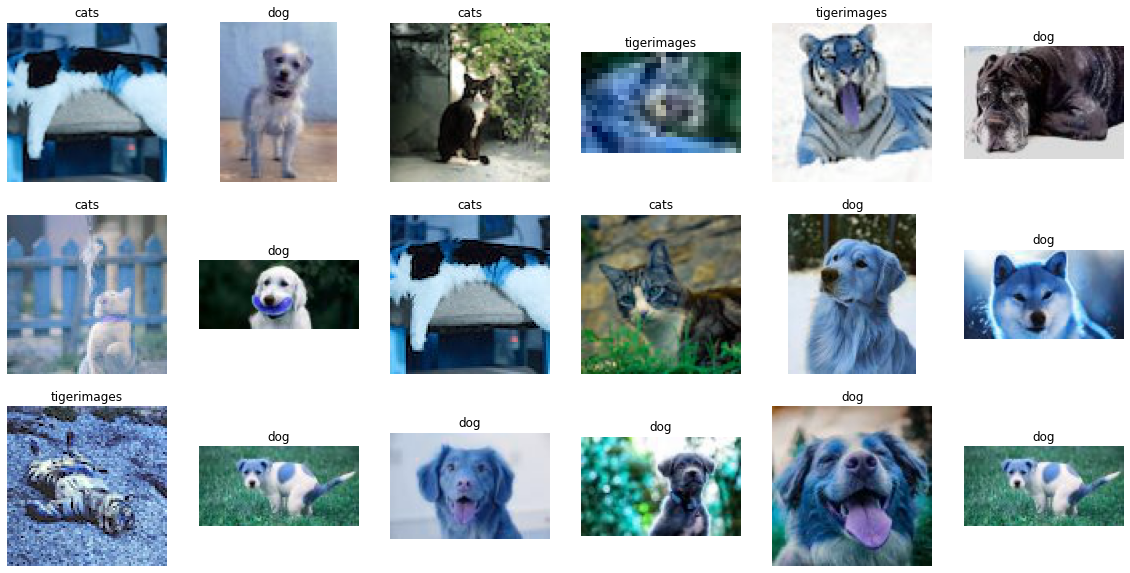

In [ ]:
plt.figure(figsize=(20,10))
for i in range(18):
  plt.subplot(3,6,i+1)
  class_name=random.choice(class_names)##add after train/
  img=view_randon_images(target_dir="/content/drive/MyDrive/Image_classification/train/",target_class=class_name)

In [ ]:
import tensorflow as tflow
model = Sequential()
pretrained_model_for_demo= tflow.keras.applications.ResNet50(include_top=False,input_shape=(180,180,3), pooling='avg',classes=7,weights='imagenet')
for each_layer in pretrained_model_for_demo.layers:
  each_layer.trainable=False
model.add(pretrained_model_for_demo)
model.add(Flatten())
model.add(Dense(512, activation='relu'))
model.add(Dense(3, activation='softmax'))

In [ ]:
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [ ]:
img_height,img_width=180,180
batch_size=32

In [ ]:
train_datagen = ImageDataGenerator(rescale= 1./255,rotation_range=10,width_shift_range=0.1,height_shift_range=0.1,shear_range=0.1,zoom_range=0.1,horizontal_flip=True,)
test_datagen = ImageDataGenerator(rescale= 1./255)
#val_datagen=ImageDataGenerator(1./255.)

In [ ]:
train_generator = train_datagen.flow_from_directory(directory = train_dir, target_size= (img_height,img_width),batch_size = batch_size,class_mode= "categorical")
test_generator = test_datagen.flow_from_directory(directory = test_dir,target_size=(img_height,img_width),batch_size = batch_size,class_mode= "categorical")
#val_generator=val_datagen.flow_from_directory(directory=val_dir,target_size=(img_height,img_width),batch_size=32,class_mode='categorical')

Found 425 images belonging to 3 classes.
Found 428 images belonging to 3 classes.


In [ ]:
model.save('model.h5')

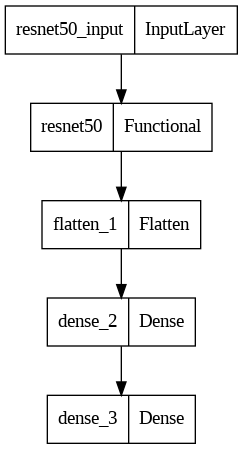

In [ ]:
plot_model(model, to_file='Emotion.png')

In [ ]:
history = model.fit_generator(train_generator,epochs=10,validation_data=test_generator,verbose=1)

<ipython-input-36-dee931b63511>:1: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  history = model.fit_generator(train_generator, epochs=10,validation_data=test_generator,


Epoch 1/10
14/14 [==============================] - 136s 10s/step - loss: 1.3823 - accuracy: 0.4141 - val_loss: 1.6272 - val_accuracy: 0.2290
Epoch 2/10
14/14 [==============================] - 79s 6s/step - loss: 1.0883 - accuracy: 0.3788 - val_loss: 1.2154 - val_accuracy: 0.2383
Epoch 3/10
14/14 [==============================] - 81s 6s/step - loss: 1.1198 - accuracy: 0.4212 - val_loss: 1.1970 - val_accuracy: 0.4112
Epoch 4/10
14/14 [==============================] - 80s 6s/step - loss: 1.1825 - accuracy: 0.4800 - val_loss: 1.1089 - val_accuracy: 0.4112
Epoch 5/10
14/14 [==============================] - 121s 9s/step - loss: 1.0878 - accuracy: 0.4635 - val_loss: 1.3209 - val_accuracy: 0.2290
Epoch 6/10
14/14 [==============================] - 81s 6s/step - loss: 0.9993 - accuracy: 0.4918 - val_loss: 1.1834 - val_accuracy: 0.3738
Epoch 7/10
14/14 [==============================] - 79s 6s/step - loss: 1.0121 - accuracy: 0.4588 - val_loss: 1.3067 - val_accuracy: 0.2827
Epoch 8/10
14/14 

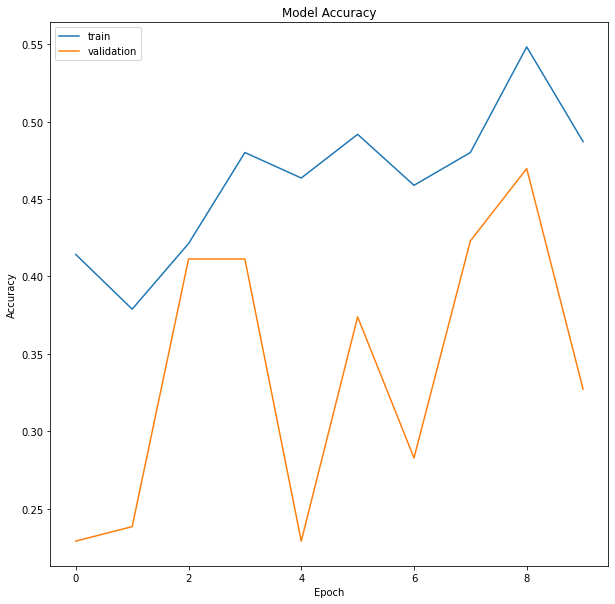

In [ ]:
plt.figure(figsize=(10,10))
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

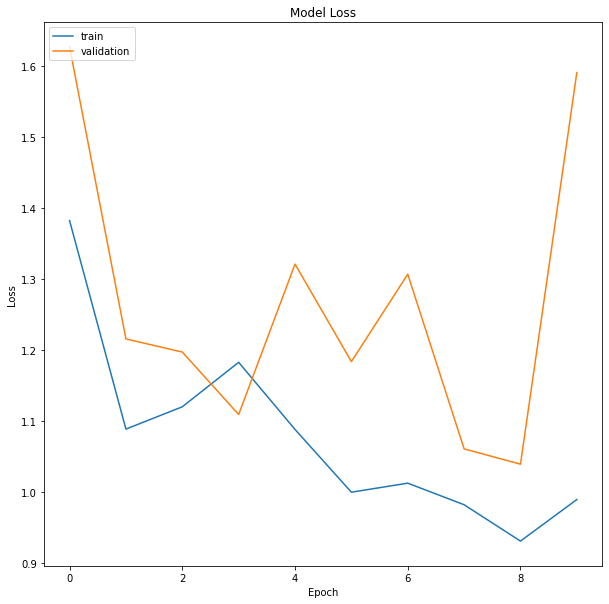

In [ ]:
plt.figure(figsize=(10,10))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()


In [ ]:
score=model.evaluate(test_generator)
print("Loss:",score[0])
print("Accuracy score:",score[1])

14/14 [==============================] - 39s 3s/step - loss: 1.5910 - accuracy: 0.3271
Loss: 1.5910377502441406
Accuracy score: 0.32710281014442444


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
from PIL import Image
def images(img):
  plt.figure(figsize=(5,5))
  plt.imshow(img)
  plt.axis("off")
  plt.show()
  img=Image.fromarray(img)
  resized_img=img.resize((180,180))
  input_img=np.expand_dims(resized_img,axis=0)
  input_img=np.array(input_img)
  input_img=input_img/255.
  pred=model.predict(input_img)
  predict=pred.argmax()
  print(predict)
  return predict

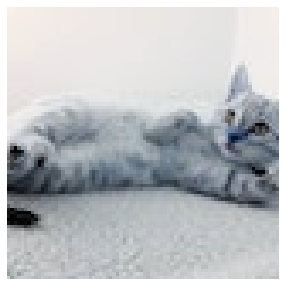

1/1 [==============================] - 1s 1s/step
2


2

In [ ]:
img=cv2.imread("/content/drive/MyDrive/Image_classification/test/cats/pexels-anel-rossouw-2558605.jpg")
images(img)

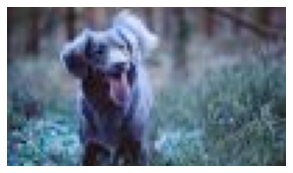

1/1 [==============================] - 0s 157ms/step
1


1

In [ ]:
img=cv2.imread("/content/drive/MyDrive/Image_classification/test/dogs/102.jpg")
images(img)